## ДЗ №1. Метрики и простейшие алгоритмы рекомендаций

In [2]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
from tqdm.auto import tqdm
from typing import List, Optional
from metric_tests import run_tests


## О задании

В этой работе мы посмотрим на то, как работают самые простые модели для рекомендаций. Как правило, они не требуют построения специальных моделей, но даже так оказываются полезны в качестве бейзлайна. Попробуем сделать предсказания с помощью EASE. Это тоже довольно простой подход, но не стоит забывать, что сложные модели могут оказаться не лучшим выбором в условиях большого количества данных. Посчитаем метрики, построим графики и подумаем, насколько хорошо эти модели вообще решают поставленную задачу.

Мы будем работать с датасетом по рекомендации фильмов от Kion MTS, который был дан для соревнования. Сперва нужно его предобработать, эта часть повторяет то, что было на семинаре. 

Датасет необходимо скачать: https://ods.ai/competitions/competition-recsys-21/data

Оттуда нужны файлы `interactions.csv` и `items.csv`

Каждое задание весит **1 балл**, если выполнено полностью и без ошибок, **0 баллов** ставится при наличии хотя бы 1 ошибки. Максимальная оценка - **10 баллов**. Шаблоны функций и классов можно менять по своему усмотрению.

In [3]:
df = pd.read_csv('interactions.csv').iloc[:-1]
df.head()

,user_id,item_id,last_watch_dt,total_dur,watched_pct
0,176549,9506,2021-05-11,4250,72.0
1,699317,1659,2021-05-29,8317,100.0
2,656683,7107,2021-05-09,10,0.0
3,864613,7638,2021-07-05,14483,100.0
4,964868,9506,2021-04-30,6725,100.0


In [4]:
df['last_watch_dt'] = (pd.to_datetime(df['last_watch_dt']) - pd.to_datetime(df['last_watch_dt']).min())
df['last_watch_dt'] = df.last_watch_dt.apply(lambda x: int(str(x).split()[0]))
df.sample(5)

,user_id,item_id,last_watch_dt,total_dur,watched_pct
5191387,207004,8484,106,1607,22.0
2901995,255680,142,41,6256,100.0
3194156,808990,1819,131,358,6.0
3149053,779827,2287,41,142,3.0
4690116,1017660,15297,129,24272,100.0


Сделаем разбиение по времени

<Axes: >

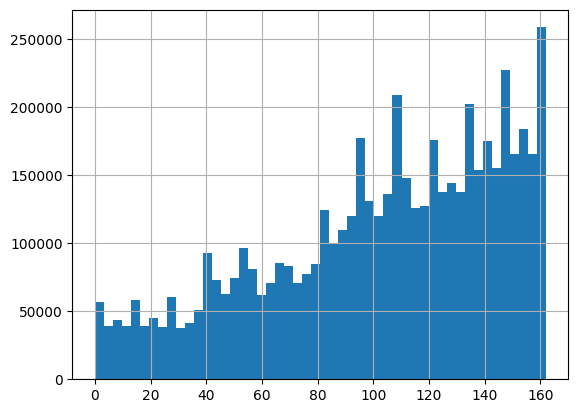

In [5]:
df.last_watch_dt.hist(bins=50)

In [6]:
train_df = df.loc[(df.last_watch_dt < 160-7)].copy()
test_df = df.loc[(df.last_watch_dt >= 160-7)].copy()

train_users = train_df.user_id.unique()
test_users = test_df.user_id.unique()

all_included = np.intersect1d(train_users, test_users)

print('число людей и там и там: ', all_included.shape[0])
print('число людей всего:', train_users.shape[0])

число людей и там и там:  134670
число людей всего: 880449


In [7]:
len(set(test_users) - set(train_users)) / len(test_users)

0.37768022181146027

И переведём всё к соединённому датасету:

In [8]:
n_users = 10000

all_included = np.random.choice(all_included, size=n_users, replace=False)

train_df = train_df.loc[train_df.user_id.isin(all_included)].copy()
test_df = test_df.loc[test_df.user_id.isin(all_included)].copy()

assert train_df.last_watch_dt.max() < test_df.last_watch_dt.min()
assert train_df.user_id.nunique() == n_users
assert test_df.user_id.nunique() == n_users

In [9]:
train_df.head()

,user_id,item_id,last_watch_dt,total_dur,watched_pct
66,750995,11699,2,12998,100.0
186,450102,3130,85,682,9.0
241,588619,9728,149,9651,100.0
251,752541,16029,44,9308,100.0
270,239600,11640,127,40991,50.0


In [10]:
train_grouped = train_df.groupby('user_id').apply(
    lambda x: [(t1, t2) for t1, t2 in sorted(zip(x.item_id,
                                                 x.last_watch_dt), key=lambda x: x[1])]
).reset_index()
train_grouped.rename({0:'train_interactions'}, axis=1, inplace=True)

test_grouped = test_df.groupby('user_id').apply(
    lambda x: [(t1, t2) for t1, t2 in sorted(zip(x.item_id,
                                                         x.last_watch_dt), key=lambda x: x[1])]
).reset_index()
test_grouped.rename({0:'test_interactions'}, axis=1, inplace=True)

train_grouped.head()

C:\Users\A1ex5\AppData\Local\Temp\ipykernel_228\1105526701.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  train_grouped = train_df.groupby('user_id').apply(
C:\Users\A1ex5\AppData\Local\Temp\ipykernel_228\1105526701.py:7: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  test_grouped = test_df.groupby('user_id').apply(


,user_id,train_interactions
0,53,"[(13865, 110), (7571, 110), (10440, 115), (161..."
1,157,"[(10440, 142), (15297, 143), (4713, 151), (124..."
2,179,"[(14, 75), (13865, 95), (10440, 95), (9728, 97)]"
3,483,"[(10440, 95), (13865, 98), (9615, 98), (2657, ..."
4,628,"[(8643, 135), (7570, 136), (6419, 142), (2483,..."


In [11]:
joined = train_grouped.merge(test_grouped)
joined.head()

,user_id,train_interactions,test_interactions
0,53,"[(13865, 110), (7571, 110), (10440, 115), (161...","[(16426, 155), (1445, 157), (15629, 157), (158..."
1,157,"[(10440, 142), (15297, 143), (4713, 151), (124...","[(16228, 156), (2616, 160)]"
2,179,"[(14, 75), (13865, 95), (10440, 95), (9728, 97)]","[(15297, 157)]"
3,483,"[(10440, 95), (13865, 98), (9615, 98), (2657, ...","[(956, 161), (5411, 162)]"
4,628,"[(8643, 135), (7570, 136), (6419, 142), (2483,...","[(6738, 154), (11338, 158)]"


In [12]:
np.random.seed(777)

class Random:

    def __init__(self):

        self.trained = False

    def fit(self, df, col='train_interactions'):

        items = set()
        for _, row in df.iterrows():
            for item, _ in row[col]:
                items.add(item)

        self.items = list(items)
        self.trained = True

    def predict(self, df, topn=10):
        assert self.trained
        return [np.random.choice(self.items, replace=False, size=topn)]*len(df)


random = Random()
random.fit(joined)

joined['random_recs'] = random.predict(joined, topn=3)
joined.head()

,user_id,train_interactions,test_interactions,random_recs
0,53,"[(13865, 110), (7571, 110), (10440, 115), (161...","[(16426, 155), (1445, 157), (15629, 157), (158...","[6032, 7935, 1249]"
1,157,"[(10440, 142), (15297, 143), (4713, 151), (124...","[(16228, 156), (2616, 160)]","[6032, 7935, 1249]"
2,179,"[(14, 75), (13865, 95), (10440, 95), (9728, 97)]","[(15297, 157)]","[6032, 7935, 1249]"
3,483,"[(10440, 95), (13865, 98), (9615, 98), (2657, ...","[(956, 161), (5411, 162)]","[6032, 7935, 1249]"
4,628,"[(8643, 135), (7570, 136), (6419, 142), (2483,...","[(6738, 154), (11338, 158)]","[6032, 7935, 1249]"


**Задание №1. Метрики и бейзлайны**

Добавьте реализацию метрик AP, RR, HR, их усреднённые версии по $U$ мы посчитаем ниже, если следовать коду с семинара, поэтому формулы немного отличаются. За имплементацию с циклами балл будет снижаться, векторизуйте! ( ͡° ͜ʖ ͡°)

$$
AP_u@k = \frac{1}{\min(k, n_u)} \sum_{i=1}^k r_u(i) p_u@i
$$
$$
p_u@k = \dfrac{1}{k}\sum_{j=1}^k r_u(j)
$$
$$
RR@k = \dfrac{1}{\text{rank}_i@k}
$$
$$
HR@k = [\exists \ y_i = 1 \ \text{among k preds}]
$$


*   $n_u$ - число айтемов, с которыми взаимодействовал юзер $u$
*   $y_i$ - релевантно ли $i$-ое предсказание, $y_i \in \{0,1\}$
* $\text{rank}_i@k$ - позиция первого релеваннтого айтема среди первых $k$ предсказаний
* HR@k - среди первых $k$ предсказаний есть хотя бы одно релевантное

Считайте, что если `topn` не задано, то берётся всегда $n_u$. 

In [21]:
def ap_metric(
    gt_items: List[int],
    predictions: List[int],
    topn: Optional[int]=None):

    if len(predictions) == 0:
        return 0
    
    if (not topn) or (topn > len(predictions)):
        topn = len(predictions)

    r = np.isin(predictions, gt_items).astype('float')[:topn]
    p_k = np.cumsum(r) / np.arange(1, len(r) + 1)
    
    return (r * p_k).sum() / min(topn, len(gt_items))

def rr_metric(
    gt_items: List[int],
    predictions: List[int],
    topn: Optional[int]=None):

    if len(predictions) == 0:
        return 0
    
    if (not topn) or (topn > len(predictions)):
        topn = len(predictions)
    
    r = np.isin(predictions, gt_items).astype('float')[:topn]
    if not r.any():
        return 0
    
    return 1 / (np.argmax(r) + 1)

def hr_metric(
    gt_items: List[int],
    predictions: List[int],
    topn: Optional[int]=None):

    if len(predictions) == 0:
        return 0
    
    if (not topn) or (topn > len(predictions)):
        topn = len(predictions)
    
    r = np.isin(predictions, gt_items).astype('float')[:topn]
    
    return float(r.any())


Для вашего удобства в файле `metric_tests.py` есть тесты, но хардкодить их, разумеется, не стоит. 

In [22]:
run_tests(ap_metric, rr_metric, hr_metric)

В следующей ячейке код, который считает и усредняет метрики по юзерам. Он взят с семинара, при желании можно его тоже модифицировать, например, векторизовать. 

In [23]:
def evaluate_recommender(df, model_preds, gt_col='test_interactions', topn=None):

    metric_values = []

    for idx, row in df.iterrows():
        gt_items = [x[0] for x in row[gt_col]]
        predictions = row[model_preds]

        ap = ap_metric(gt_items, predictions, topn)
        rr = rr_metric(gt_items, predictions, topn)
        hr = hr_metric(gt_items, predictions, topn)

        metric_values.append((ap, rr, hr))

    return {'map': np.mean([x[0] for x in metric_values]),
            'mrr': np.mean([x[1] for x in metric_values]),
            'hr': np.mean([x[2] for x in metric_values])}

Если вы всё сделали правильно, рандомные предсказания должны дать хоть какое-то качество, но не очень большое.

In [25]:
evaluate_recommender(joined, model_preds='random_recs')

{'map': np.float64(5.555555555555556e-05),
 'mrr': np.float64(0.00016666666666666666),
 'hr': np.float64(0.0005)}

In [26]:
class TopPopular:

    def __init__(self):

        self.trained = False

    def fit(self, df, col='train_interactions'):

        counts = {}
        for _, row in df.iterrows():
            for item, _ in row[col]:
                if item in counts:
                    counts[item] += 1
                else:
                    counts[item] = 1

        counts = sorted(counts.items(), key=lambda x: x[1], reverse=True)

        self.recommenations = [x[0] for x in counts]
        self.trained = True

    def predict(self, df, topn=10)  -> List[np.ndarray]:

        assert self.trained
        return [self.recommenations[:topn]]*len(df)


toppop = TopPopular()
toppop.fit(joined)

joined['toppopular_recs'] = toppop.predict(joined)
joined.head()

,user_id,train_interactions,test_interactions,random_recs,toppopular_recs
0,53,"[(13865, 110), (7571, 110), (10440, 115), (161...","[(16426, 155), (1445, 157), (15629, 157), (158...","[6032, 7935, 1249]","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ..."
1,157,"[(10440, 142), (15297, 143), (4713, 151), (124...","[(16228, 156), (2616, 160)]","[6032, 7935, 1249]","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ..."
2,179,"[(14, 75), (13865, 95), (10440, 95), (9728, 97)]","[(15297, 157)]","[6032, 7935, 1249]","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ..."
3,483,"[(10440, 95), (13865, 98), (9615, 98), (2657, ...","[(956, 161), (5411, 162)]","[6032, 7935, 1249]","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ..."
4,628,"[(8643, 135), (7570, 136), (6419, 142), (2483,...","[(6738, 154), (11338, 158)]","[6032, 7935, 1249]","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ..."


Самые популярные предсказания должны показать более высокое качество.

In [27]:
evaluate_recommender(joined, model_preds='toppopular_recs')

{'map': np.float64(0.06578132927059713),
 'mrr': np.float64(0.1192770634920635),
 'hr': np.float64(0.279)}

**Задание №2. Рекомендации в окне**

Здесь необходимо переделать метод рекомендации по популярности так, что популярность считается только за какое-то более свежее временное окно. Под окном подразумевается какой-то временной промежуток, например, ближайший месяц. Соответственно, всё что за его пределами, не учитывается.

In [28]:
joined

,user_id,train_interactions,test_interactions,random_recs,toppopular_recs
0,53,"[(13865, 110), (7571, 110), (10440, 115), (161...","[(16426, 155), (1445, 157), (15629, 157), (158...","[6032, 7935, 1249]","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ..."
1,157,"[(10440, 142), (15297, 143), (4713, 151), (124...","[(16228, 156), (2616, 160)]","[6032, 7935, 1249]","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ..."
2,179,"[(14, 75), (13865, 95), (10440, 95), (9728, 97)]","[(15297, 157)]","[6032, 7935, 1249]","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ..."
3,483,"[(10440, 95), (13865, 98), (9615, 98), (2657, ...","[(956, 161), (5411, 162)]","[6032, 7935, 1249]","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ..."
4,628,"[(8643, 135), (7570, 136), (6419, 142), (2483,...","[(6738, 154), (11338, 158)]","[6032, 7935, 1249]","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ..."
...,...,...,...,...,...
9995,1096920,"[(5648, 91)]","[(9728, 157)]","[6032, 7935, 1249]","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ..."
9996,1096925,"[(15297, 84), (12995, 97), (12173, 101), (4436...","[(15679, 153), (13018, 153), (9728, 154), (619...","[6032, 7935, 1249]","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ..."
9997,1097007,"[(4880, 65)]","[(1916, 155)]","[6032, 7935, 1249]","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ..."
9998,1097290,"[(10440, 140)]","[(5754, 153), (15761, 154), (7829, 160), (734,...","[6032, 7935, 1249]","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ..."


In [29]:
class TopPopularWeighted(TopPopular):

    def __init__(self, min_window=2):
        super().__init__()
        self.min_window = min_window

    def get_max_dt(self, df, col):
        max_dt = 0
        for _, row in df.iterrows():
            for _, dt in row[col]:
                max_dt = max(max_dt, dt)
        return max_dt

    def fit(self, df, col='train_interactions'):
        counts = {}
        max_dt = self.get_max_dt(df, col)
        for _, row in df.iterrows():
            for item, dt in row[col]:
                if (max_dt - dt) > self.min_window:
                    continue
                if item in counts:
                    counts[item] += 1
                else:
                    counts[item] = 1
        
        counts = sorted(counts.items(), key=lambda x: x[1], reverse=True)

        self.recommenations = [x[0] for x in counts]
        self.trained = True

    def predict(self, df, topn=10)  -> List[np.ndarray]:
    
        assert self.trained
        return [self.recommenations[:topn]]*len(df)

toppopweighted = TopPopularWeighted()
toppopweighted.fit(joined)

joined['toppopweighted_recs'] = toppopweighted.predict(joined)
joined.head()

,user_id,train_interactions,test_interactions,random_recs,toppopular_recs,toppopweighted_recs
0,53,"[(13865, 110), (7571, 110), (10440, 115), (161...","[(16426, 155), (1445, 157), (15629, 157), (158...","[6032, 7935, 1249]","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ...","[10440, 15297, 9728, 7793, 13865, 4151, 341, 3..."
1,157,"[(10440, 142), (15297, 143), (4713, 151), (124...","[(16228, 156), (2616, 160)]","[6032, 7935, 1249]","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ...","[10440, 15297, 9728, 7793, 13865, 4151, 341, 3..."
2,179,"[(14, 75), (13865, 95), (10440, 95), (9728, 97)]","[(15297, 157)]","[6032, 7935, 1249]","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ...","[10440, 15297, 9728, 7793, 13865, 4151, 341, 3..."
3,483,"[(10440, 95), (13865, 98), (9615, 98), (2657, ...","[(956, 161), (5411, 162)]","[6032, 7935, 1249]","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ...","[10440, 15297, 9728, 7793, 13865, 4151, 341, 3..."
4,628,"[(8643, 135), (7570, 136), (6419, 142), (2483,...","[(6738, 154), (11338, 158)]","[6032, 7935, 1249]","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ...","[10440, 15297, 9728, 7793, 13865, 4151, 341, 3..."


Теперь постройте графики зависимости значений трёх метрик (AP@k, RR@k, HR@k) от размера окна. 

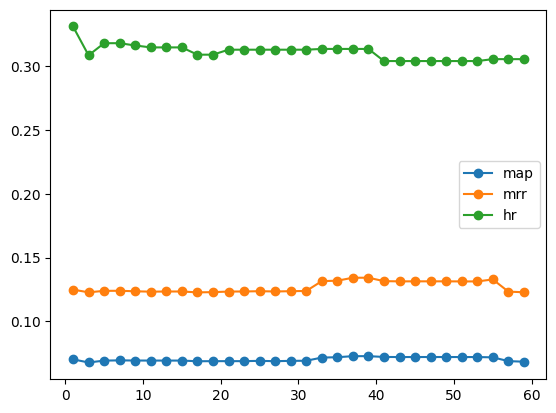

In [30]:
n_window = np.arange(1,60,2)

map = []
mrr = []
hr = []
for n in n_window:
    toppopweighted = TopPopularWeighted(min_window=n)
    toppopweighted.fit(joined)

    joined['toppopweighted_recs'] = toppopweighted.predict(joined)
    
    temp_metrics = evaluate_recommender(joined, model_preds='toppopweighted_recs')
    map += [temp_metrics['map']]
    mrr += [temp_metrics['mrr']]
    hr += [temp_metrics['hr']]

plt.plot(n_window, map, label='map', marker='o')
plt.plot(n_window, mrr, label='mrr', marker='o')
plt.plot(n_window, hr, label='hr', marker='o')
plt.legend()

Подумайте и ответьте, как размер окна влияет на качество рекомендаций. Какое значение наилучшее, есть ли у этого разумное объяснение?

**Ответ:** Маленькое окно берёт только самые свежие взаимодействия - модель рекомендует то, что популярно прямо сейчас. Но при слишком маленьком окне мало данных, поэтому MAP/MRR низкие. Лучшее значение для каждой метрики определять отдельно по графику.

**Задание №3. Метрики и k.**

Постройте зависимость значений MAP@K, MRR@K, HR@K для метода рекомендации по популярности. Возьмите какие-нибудь k, например, от 1 до 100, переберите значения и покажите на линейном графике. 

In [31]:
joined['toppopular_recs'] = toppop.predict(joined, topn=100)

In [32]:
map = []
mrr = []
hr = []

for k in np.arange(1,60,2):
    
    temp_metrics = evaluate_recommender(joined, model_preds='toppopweighted_recs', topn=k)
    
    map += [temp_metrics['map']]
    mrr += [temp_metrics['mrr']]
    hr += [temp_metrics['hr']]

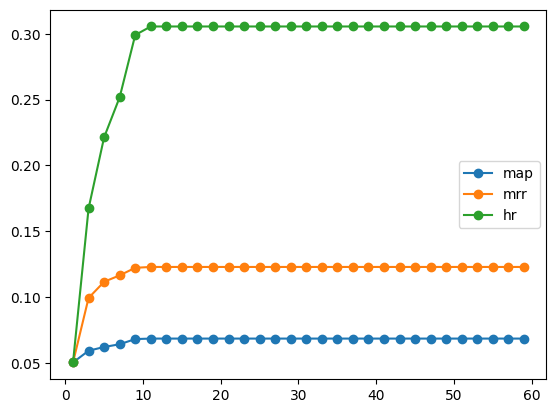

In [33]:
k = np.arange(1,60,2)

plt.plot(k, map, label='map', marker='o')
plt.plot(k, mrr, label='mrr', marker='o')
plt.plot(k, hr, label='hr', marker='o')
plt.legend()

Хорошенько подумайте и ответьте на вопросы ниже.

---

3.1 Какие из метрик являются монотонными функциями по top-K? Объясните, почему они являются монотонными? \

**HR@k** - монотонно неубывающая. Если среди первых k предсказаний есть хотя бы один релевантный, то при увеличении k до k+1 он никуда не денется. HR может только вырасти или остаться тем же, но никогда не упасть.\
**MRR@k** - монотонно неубывающая. rank_i@k - позиция первого релевантного среди первых k. При увеличении k эта позиция либо остаётся той же (если релевантный уже был найден), либо уменьшается (если новый элемент оказался релевантным и стоит раньше). \
**MAP@k** - монотонно неубывающая.  
​

**Ответ:** Все 3 монотонно неубывающие. Ввиду устройства самих метрик. 

---
3.2 Объясните по каждой метрике, как можно интерпретировать ее график? То есть, что можно сказать про связь изменения метрики c возможными пользовательскими сценариями, например,скроллингом ленты новостей. 


**Ответ:** По каждому из графиков можно найти некое оптимальное k после которого рост практически останавливается. Разные метрики также могут отражать интерес разных групп пользователей e.g. метрика MRR больше отражает желание "нетерпеливой" аудитории показывая скорость рекоммендации первого релевантноо объекта. 

---

3.3 Как вы думаете, почему графики выглядят именно так? Должны ли они возрастать/убывать, от чего это может зависеть? (Тут вам может помочь дополнительный анализ данных)\
**Ответ:** \
Графики обязаны возрастать, но форма кривой зависит от данных: 
* Резкий рост в начале (k=1..10) - модель хорошо ранжирует: релевантные предметы действительно оказываются в топе.

* Быстрое насыщение (плато после k≈10) - у большинства пользователей мало релевантных предметов в принципе (sparse ground truth). Если $n_u$ маленькое, то после  $k≥n$ метрика уже не может расти.


* Почему не убывают? - потому что это кумулятивные метрики по определению (см. 3.1). Убывать они могли бы только если бы мы меняли сам список предсказаний, а не просто увеличивали k.

---

**Задание №4. Интерпретация рейтингов**

Возьмите названия фильмов/сериалов из `items.csv`, выделите 5 различных сценариев изменения популярности у фильмов, аргументируйте (например, графиком или статистикой) и проинтерпретируейте их (почему популярность для этого фильма меняется так). Обратите внимание, что надо найти именно разные паттерны изменения вероятностей. 

In [35]:
items = pd.read_csv('items.csv')[['item_id','title']].copy()
items.head()

,item_id,title
0,10711,Поговори с ней
1,2508,Голые перцы
2,10716,Тактическая сила
3,7868,45 лет
4,16268,Все решает мгновение


Пример:

1917


<Axes: >

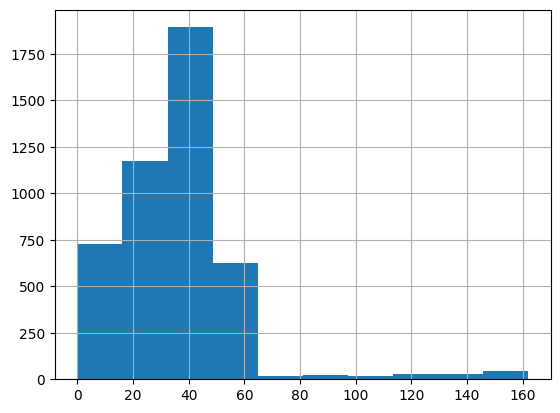

In [36]:
popular_items = df.item_id.value_counts()[:300].index.tolist()
sampled_id = np.random.choice(popular_items)

sampled_id = 3402

interactions = df.loc[df.item_id==sampled_id].copy()
name = items.loc[items.item_id==sampled_id].title.values[0]
print(name)
interactions.last_watch_dt.hist()

Фильм 1917 какое-то время набирал популярность, потом видим резкое падение (кстати, с какой даты?). Возможно, это связано с ограничением доступности этого фильма для части пользователей, периодом проката фильма / рекламной кампании или другой причиной. 

Добавьте 5 своих примеров ниже. Опишите, как вы их искали. 

[1] Небеса подождут
[2] Немцы
[3] Мстители: Война бесконечности
[4] 13 грехов
[5] Радиовспышка


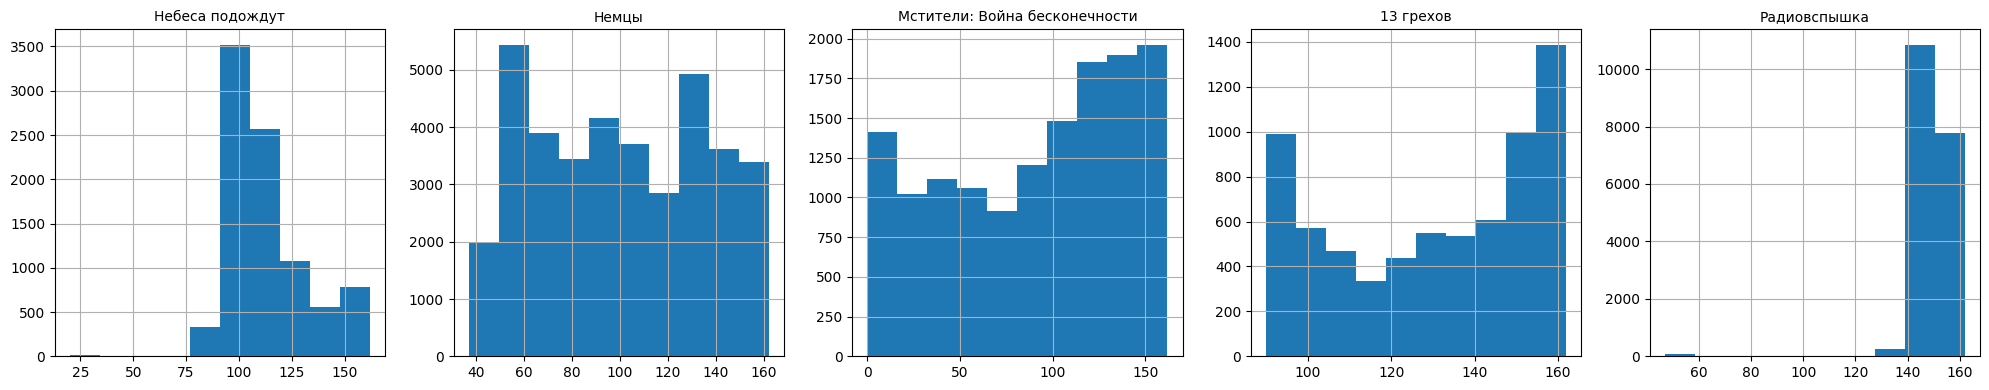

In [40]:
fig, axes = plt.subplots(nrows=1, ncols=5, figsize=(20, 4))
for idx in range(5):
    sampled_id = np.random.choice(popular_items)
    interactions = df.loc[df.item_id == sampled_id].copy()
    name = items.loc[items.item_id == sampled_id].title.values[0]
    print(f"[{idx+1}] {name}")
    interactions.last_watch_dt.hist(ax=axes[idx])
    axes[idx].set_title(name, fontsize=10)
plt.tight_layout()
plt.show()

**Задание №5. User-item encoding**

Теперь, создайте матрицу интеракций user-item по примеру из семинара. Вам нужно в итоге получить разреженную матрицу (sparse matrix), в которой в качестве строк будут пользователи, в качестве колонок - айтемы. Не забудьте перекодировать пользователей и айтемы через энкодер. В отличие от семинара, оставьте в матрице только юзеров и айтемы, которые встречались в матрице > 4 раз.

Важно: когда вы отфильтруете юзеров на встречаемость > 4 раз, вы удалите какие-то айтемы, которые теперь станут встречаться меньше 5 раз. Поэтому у вас перестанет выполняться второе условие на минимальное число интеракций с айтемом. Тогда вам надо опять отфильтровать айтемы на встречаемость, но это снова может нарушить условие для юзеров. В таком случае, вам надо написать итеративный алгоритм до сходимости, пока требования не будут выполняться в обеих колонках. 

In [42]:
counters = df['user_id'].value_counts()

In [43]:
df[df['user_id'].isin(counters[counters>=4].index)]

,user_id,item_id,last_watch_dt,total_dur,watched_pct
0,176549,9506,59,4250,72.0
1,699317,1659,77,8317,100.0
3,864613,7638,114,14483,100.0
5,1032142,6686,61,11286,100.0
6,1016458,354,154,1672,25.0
...,...,...,...,...,...
5476243,497899,9629,77,45,1.0
5476244,438585,7829,142,6804,100.0
5476245,786732,4880,60,753,0.0
5476247,546862,9673,31,2308,49.0


In [44]:
def filter_column(df, col, min_freq):
    counters = df[col].value_counts()
    return df[df[col].isin(counters[counters>=min_freq].index)].copy()

def filter_dataframe(df, cols, min_freq=5):
    df = df.copy()
    len_prev = len(df)
    while True:
        for col in cols:
            df = filter_column(df, col, min_freq)
        
        if len(df)!=len_prev:
            len_prev = len(df)
        else:
            break
    
    return df

filtered_train = filter_dataframe(train_df.copy(), ['user_id','item_id'], 4)

In [45]:
filtered_train

,user_id,item_id,last_watch_dt,total_dur,watched_pct
66,750995,11699,2,12998,100.0
186,450102,3130,85,682,9.0
241,588619,9728,149,9651,100.0
251,752541,16029,44,9308,100.0
270,239600,11640,127,40991,50.0
...,...,...,...,...,...
5476026,1026152,758,151,897,14.0
5476074,190797,15981,128,13982,100.0
5476092,280117,14431,3,377,7.0
5476133,329210,6155,83,8912,100.0


In [46]:
def df_encode(df):
    item2id = {k:v for v, k in enumerate(df.item_id.unique())}
    user2id = {k:v for v, k in enumerate(df.user_id.unique())}

    id2item = {k:v for v, k in item2id.items()}
    id2user = {k:v for v, k in user2id.items()}

    df['user_id'] = df.user_id.apply(lambda x: user2id[x])
    df['item_id'] = df.item_id.apply(lambda x: item2id[x])
    return df, item2id, user2id, id2item, id2user

filtered_train, item2id, user2id, id2item, id2user = df_encode(filtered_train)
filtered_train.sample(5)

,user_id,item_id,last_watch_dt,total_dur,watched_pct
465594,3195,940,147,204,4.0
4015114,1741,865,48,2918,37.0
4978537,376,90,142,6010,100.0
225634,2699,1301,119,73,1.0
3662412,1833,1224,126,5732,87.0


In [47]:
from scipy import sparse as sps

matrix = sps.coo_matrix(
    (np.ones(filtered_train.shape[0]), (filtered_train['user_id'], filtered_train['item_id'])),
    shape=(len(user2id), len(item2id)),
)
matrix

<COOrdinate sparse matrix of dtype 'float64'
	with 106817 stored elements and shape (6544, 3395)>

**Задание №6. Интеракции и частота**

Постройте график зависимости количества айтемов и юзеров от значений (порогов) фильтров на встречаемость в матрице интеракций. То есть, нужно выполнить задание №5 для нескольких значений `min_freq` и построить график зависимости числа оставшихся айтемов и юзеров от этого параметра. 

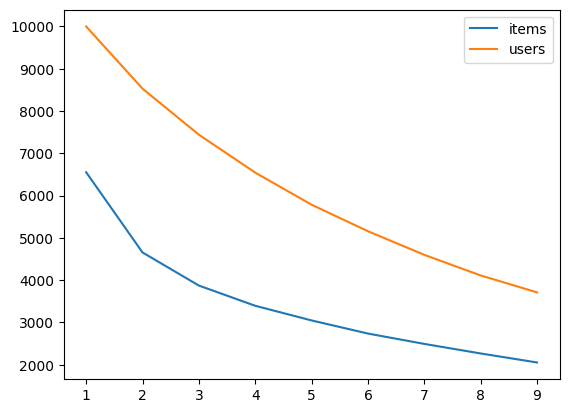

In [48]:
k = np.arange(1,10,1)

items = []
users = []
for i in k:
    filtered_train = filter_dataframe(train_df.copy(), ['user_id','item_id'], i)
    items.append(len(filtered_train['item_id'].unique()))
    users.append(len(filtered_train['user_id'].unique()))
    
plt.plot(k,items, label = 'items')
plt.plot(k,users, label = 'users')
plt.legend()

**Задание №7. EASE**

Реализуйте EASE, постройте рекомендации для юзеров. Сравните все имплементированные ранее метрики качества с `TopPopular` для некоторого набора k. 

Реализацию можно взять из семинара. Можно реализовать по статье https://arxiv.org/pdf/1905.03375.pdf. Можно взять и адаптировать из RecBole https://github.com/RUCAIBox/RecBole.

In [49]:
#%%time

# Обучаем конечную модель
# Мы взяли реализацию из RecBole
#
def fit_ease(X, reg_weight=1000):
    if sps.issparse(X): 
        X = X.tocsc()
    else:
        X = sps.csc_matrix(X)
        
    G = (X.T @ X).toarray()
    diagIndices = np.diag_indices(G.shape[0])
    G[diagIndices] += reg_weight
    P = np.linalg.inv(G)
    B = P / (-np.diag(P))
    B[diagIndices] = 0


    return B


w = fit_ease(matrix)

Далее, вам надо реализовать функцию получения предсказаний. У вас есть обученная матрица весов, которую можно использовать для получения предсказаний. Для этого нужно построить вектор интеракций пользователя и умножить его на матрицу весов.

In [50]:
def get_preds(x, item2id, id2item, w,top_n=5):

    user_vector = np.zeros(len(w))
    idx_list = []

    for num in x:
        item = num[0]
        if item in item2id: 
            idx = item2id[item]
            idx_list.append(idx)
            user_vector[idx] = 1
            
    result = user_vector @ w
    result[idx_list] = -np.inf
    top_result = np.argsort(result)[::-1][:top_n]

    decoded = []
    for idx in top_result:
        decoded.append(id2item[idx])

    return decoded


joined['ease_preds'] = joined.train_interactions.apply(lambda x: get_preds(x, item2id, id2item, w, top_n=100))
joined.head()

,user_id,train_interactions,test_interactions,random_recs,toppopular_recs,toppopweighted_recs,ease_preds
0,53,"[(13865, 110), (7571, 110), (10440, 115), (161...","[(16426, 155), (1445, 157), (15629, 157), (158...","[6032, 7935, 1249]","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ...","[10440, 9728, 15297, 13865, 3734, 4151, 2657, ...","[9728, 4880, 2657, 12192, 9996, 8636, 4495, 68..."
1,157,"[(10440, 142), (15297, 143), (4713, 151), (124...","[(16228, 156), (2616, 160)]","[6032, 7935, 1249]","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ...","[10440, 9728, 15297, 13865, 3734, 4151, 2657, ...","[4151, 13865, 9728, 2657, 142, 3734, 12192, 99..."
2,179,"[(14, 75), (13865, 95), (10440, 95), (9728, 97)]","[(15297, 157)]","[6032, 7935, 1249]","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ...","[10440, 9728, 15297, 13865, 3734, 4151, 2657, ...","[15297, 3734, 9996, 2657, 4151, 142, 8636, 488..."
3,483,"[(10440, 95), (13865, 98), (9615, 98), (2657, ...","[(956, 161), (5411, 162)]","[6032, 7935, 1249]","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ...","[10440, 9728, 15297, 13865, 3734, 4151, 2657, ...","[4151, 9728, 4880, 9996, 12192, 8636, 4495, 68..."
4,628,"[(8643, 135), (7570, 136), (6419, 142), (2483,...","[(6738, 154), (11338, 158)]","[6032, 7935, 1249]","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ...","[10440, 9728, 15297, 13865, 3734, 4151, 2657, ...","[9728, 13865, 16166, 6809, 6455, 12173, 10440,..."


In [51]:
map = []
mrr = []
hr = []
map_ease = []
mrr_ease = []
hr_ease = []
for k in np.arange(1,60,2):
    
    temp_metrics = evaluate_recommender(joined, model_preds='toppopular_recs', topn=k)
    ease_metrics = evaluate_recommender(joined, model_preds='ease_preds', topn=k)

    map += [temp_metrics['map']]
    mrr += [temp_metrics['mrr']]
    hr += [temp_metrics['hr']]

    map_ease += [ease_metrics['map']]
    mrr_ease += [ease_metrics['mrr']]
    hr_ease += [ease_metrics['hr']]




In [52]:
k = np.arange(1,60,2)

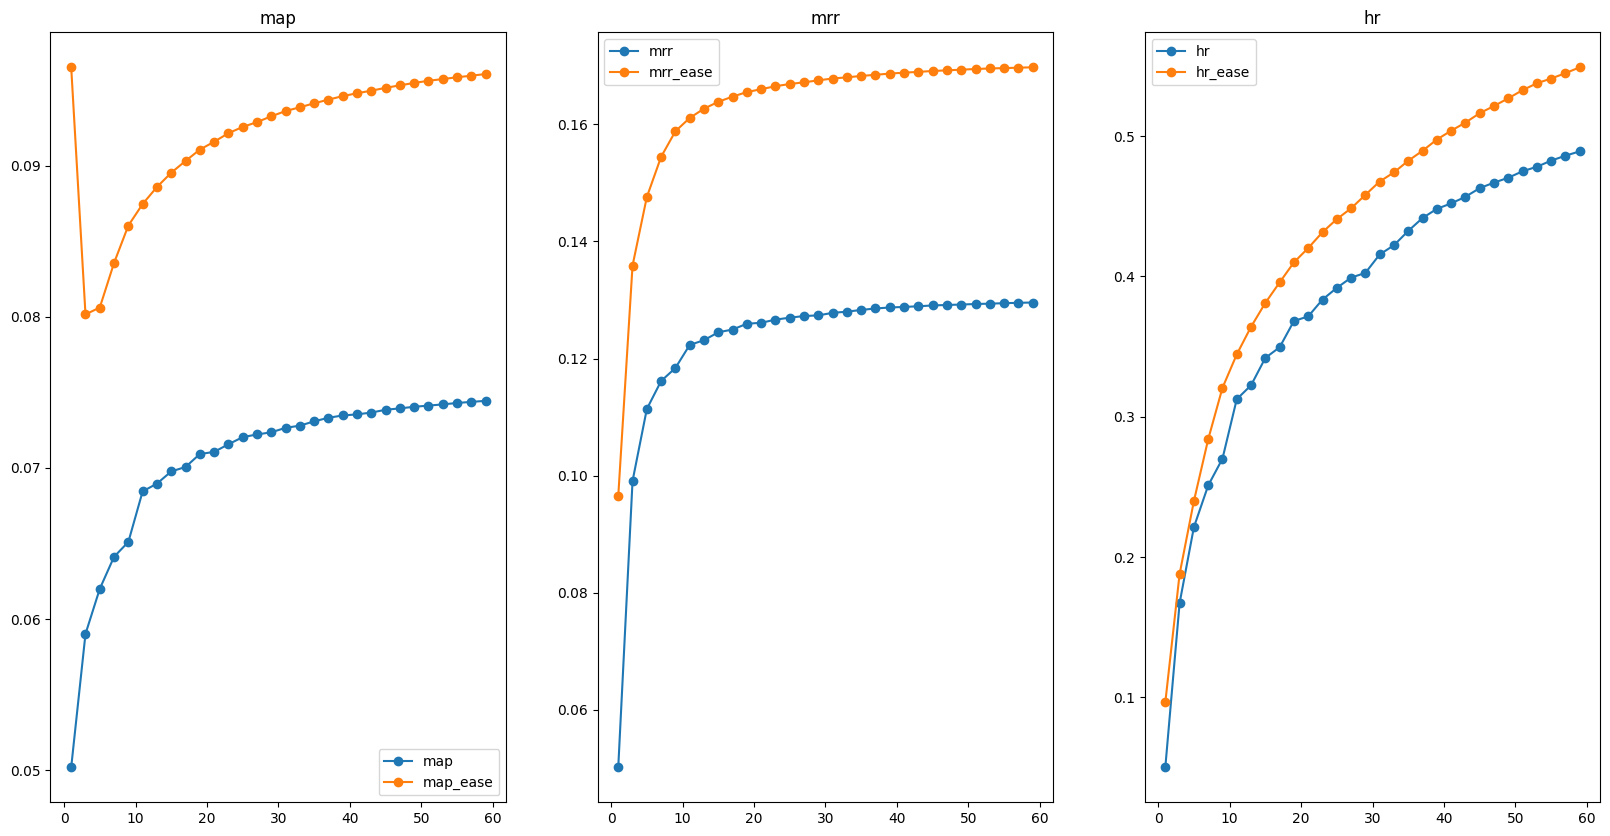

In [53]:
plt.figure(figsize=(20,10))
plt.subplot(1,3,1)
plt.plot(k, map, label='map', marker='o')
plt.plot(k, map_ease, label='map_ease', marker='o')
plt.title('map')
plt.legend()
plt.subplot(1,3,2)
plt.plot(k, mrr, label='mrr', marker='o')
plt.plot(k, mrr_ease, label='mrr_ease', marker='o')
plt.title('mrr')
plt.legend()
plt.subplot(1,3,3)
plt.plot(k, hr, label='hr', marker='o')
plt.plot(k, hr_ease, label='hr_ease', marker='o')
plt.title('hr')
plt.legend()



Сделайте выводы — какой алгоритм работает лучше?

**Ответ:**
ease лучше, потому что он для каждого персональный

**Задание №8. Тюнинг**

Переберите различные значения гиперпараметра коэффициента регуляризации у EASE и постройте графики, как в задании №6. Постарайтесь "затюнить" EASE как можно лучше. Возьмите разумное число гиперпараметров - хотя бы штук 20 по логарифмической сетке, либо используйте более хитрые алгоритмы оптимизации. 

In [54]:
map = []
mrr = []
hr = []
k = 10
reg_weights = np.logspace(0,5,20)
for reg_weight in reg_weights:
    w = fit_ease(matrix,reg_weight=reg_weight)
    joined['easeweighted_recs'] = joined.train_interactions.apply(lambda x: get_preds(x, item2id, id2item, w, top_n=k))

    ease_metrics = evaluate_recommender(joined, model_preds='easeweighted_recs', topn=k)

    map += [ease_metrics['map']]
    mrr += [ease_metrics['mrr']]
    hr += [ease_metrics['hr']]
    


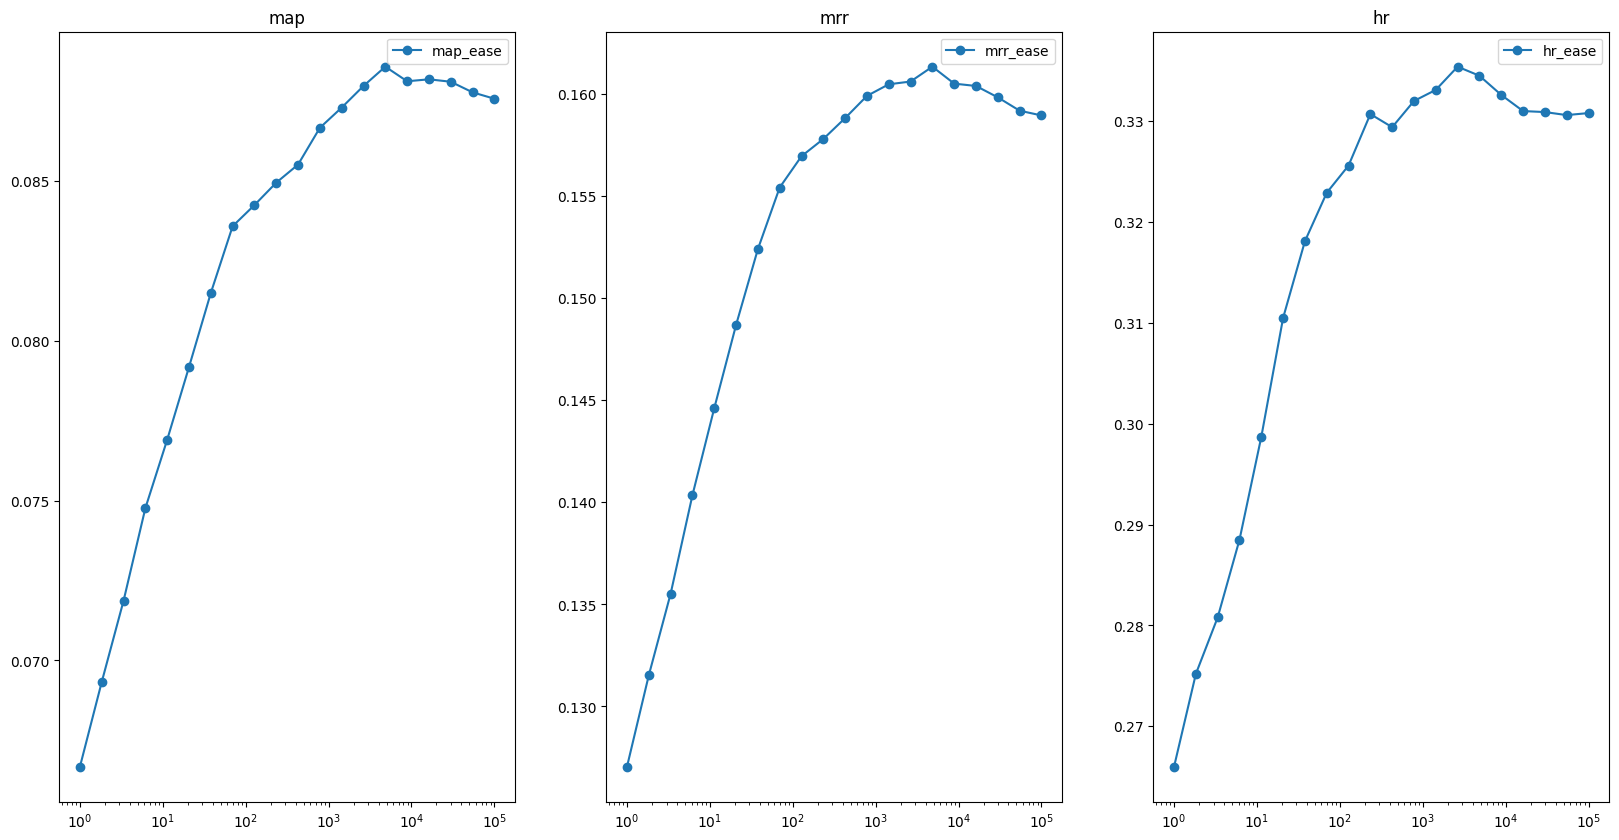

In [56]:
plt.figure(figsize=(20,10))
plt.subplot(1,3,1)
plt.xscale('log')
plt.plot(reg_weights, map, label='map_ease', marker='o')
plt.title('map')
plt.legend()
plt.subplot(1,3,2)
plt.xscale('log')
plt.plot(reg_weights, mrr, label='mrr_ease', marker='o')
plt.title('mrr')
plt.legend()
plt.subplot(1,3,3)
plt.xscale('log')
plt.plot(reg_weights, hr, label='hr_ease', marker='o')
plt.title('hr')
plt.legend()



Ответьте на следующие вопросы:

8.1 Какое значение гиперпараметра является наилучшим? 


**Ответ:**
Для всех метрик наулчшее значение гиперпараметра = $10^3$ \
8.2 Что еще интересного вы можете сказать по графикам? Может быть, что-то свзяанное с распределением параметров, влиянием на отдельные метрики, скоростью тюнинга?

**Ответ:**
После значения гиперпараметра = $10^3$ (пороговое значение), улчшения не происходит.  

**Задание №9. EASE и topk**

В лекции №2 говорилось, что качество у EASE растет с ослаблением фильтра на число айтемов. В этом задании постройте кривые метрик качества MAP/MRR/HR в зависимости от topk (например, от 1 до 100 с некоторым шагом), где кривая параметризована минимальным требуемым значением встречаемости user/item (из задания №6). Опишите свои выводы.

In [61]:
map = []
mrr = []
hr = []
min_freq = [4,6,8,15]
metrix = {}

for i in min_freq:
    metrix[i] = {'map': [], 'mrr': [], 'hr': []}
    filtered_train = filter_dataframe(train_df.copy(), ['user_id', 'item_id'], i)
    filtered_train, item2id, user2id, id2item, id2user = df_encode(filtered_train)

    matrix = sps.coo_matrix(
        (np.ones(filtered_train.shape[0]), (filtered_train['user_id'], filtered_train['item_id'])),
        shape=(len(user2id), len(item2id)),
    )
    w = fit_ease(matrix, reg_weight=1000)

    joined['easeweighted_recs'] = joined.train_interactions.apply(
        lambda x: get_preds(x, item2id, id2item, w, top_n=60)
    )

    for k in np.arange(1, 60, 2):
        ease_metrics = evaluate_recommender(
            joined, 
            model_preds='easeweighted_recs',  # ✅ правильное имя
            topn=k
        )
        metrix[i]['map'].append(ease_metrics['map'])
        metrix[i]['mrr'].append(ease_metrics['mrr'])
        metrix[i]['hr'].append(ease_metrics['hr'])


In [62]:
metrix[min_freq[0]]['map']

[np.float64(0.0965),
 np.float64(0.08015555555555555),
 np.float64(0.08060797222222223),
 np.float64(0.08356164115646257),
 np.float64(0.08603153675359032),
 np.float64(0.0874558954815627),
 np.float64(0.08858136837421651),
 np.float64(0.08952572624375846),
 np.float64(0.09030367056459206),
 np.float64(0.09105366194854914),
 np.float64(0.09157371992423011),
 np.float64(0.09213928825855856),
 np.float64(0.09255453785490274),
 np.float64(0.09287254645330405),
 np.float64(0.09325818500285736),
 np.float64(0.09360447641950494),
 np.float64(0.09385449399184674),
 np.float64(0.09411728756152175),
 np.float64(0.09435999939911019),
 np.float64(0.09459382898681545),
 np.float64(0.09478086501419107),
 np.float64(0.09495400409876083),
 np.float64(0.09513816684947592),
 np.float64(0.09530692496653644),
 np.float64(0.09546371529082846),
 np.float64(0.0956081022006271),
 np.float64(0.0957193991462163),
 np.float64(0.09584018982548322),
 np.float64(0.09594234282813806),
 np.float64(0.0960539330066294

In [63]:
k = np.arange(1,60,2)

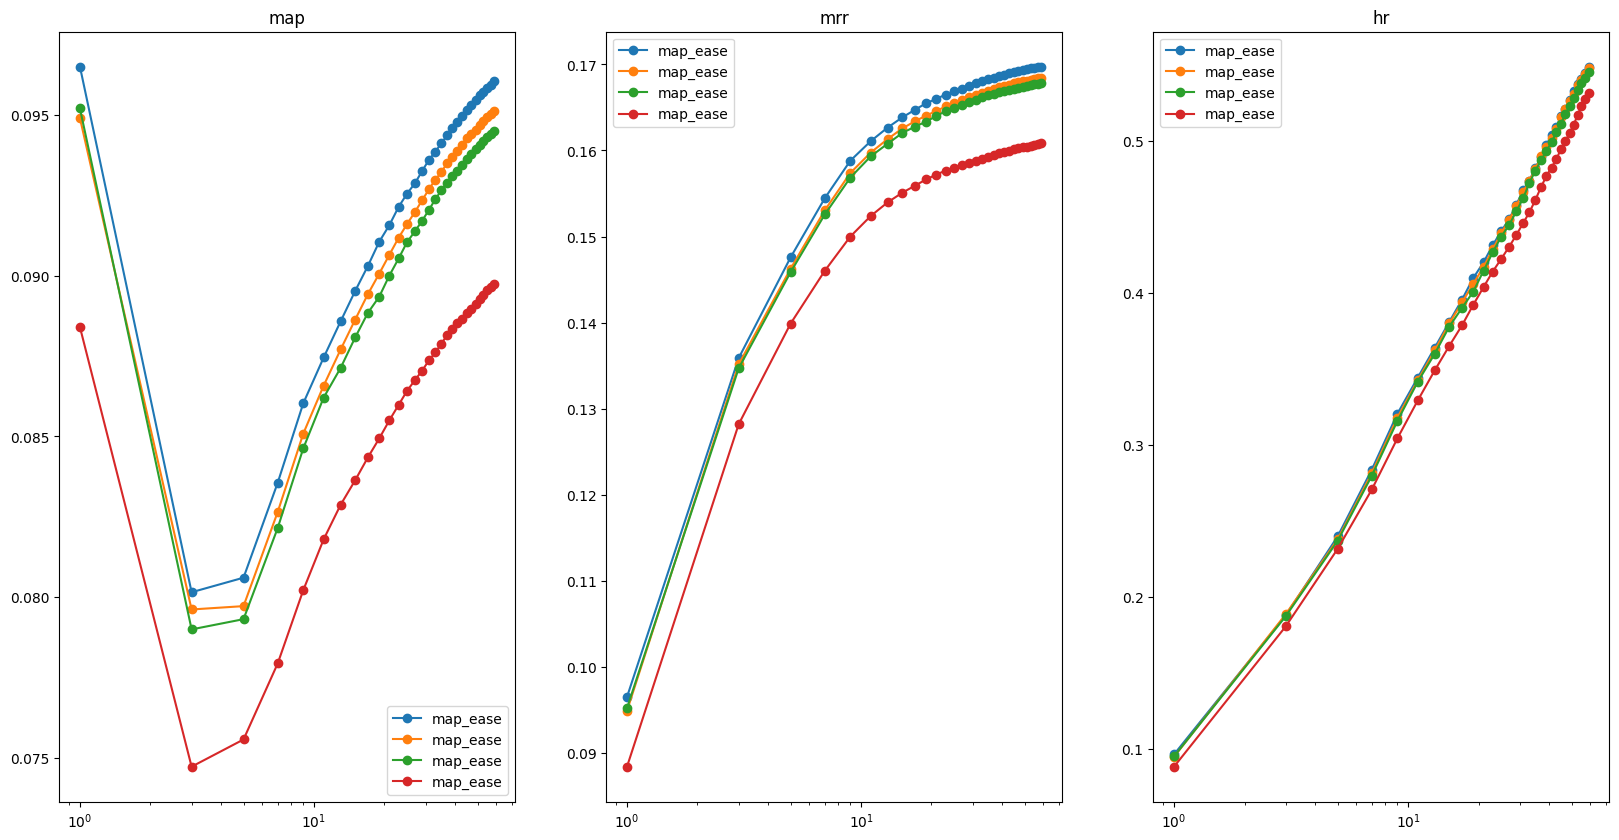

In [64]:
plt.figure(figsize=(20,10))
plt.subplot(1,3,1)
plt.xscale('log')
plt.plot(k, metrix[min_freq[0]]['map'], label='map_ease', marker='o')
plt.plot(k, metrix[min_freq[1]]['map'], label='map_ease', marker='o')
plt.plot(k, metrix[min_freq[2]]['map'], label='map_ease', marker='o')
plt.plot(k, metrix[min_freq[3]]['map'], label='map_ease', marker='o')
plt.title('map')
plt.legend()
plt.subplot(1,3,2)
plt.xscale('log')
plt.plot(k, metrix[min_freq[0]]['mrr'], label='map_ease', marker='o')
plt.plot(k, metrix[min_freq[1]]['mrr'], label='map_ease', marker='o')
plt.plot(k, metrix[min_freq[2]]['mrr'], label='map_ease', marker='o')
plt.plot(k, metrix[min_freq[3]]['mrr'], label='map_ease', marker='o')
plt.title('mrr')
plt.legend()
plt.subplot(1,3,3)
plt.xscale('log')
plt.plot(k, metrix[min_freq[0]]['hr'], label='map_ease', marker='o')
plt.plot(k, metrix[min_freq[1]]['hr'], label='map_ease', marker='o')
plt.plot(k, metrix[min_freq[2]]['hr'], label='map_ease', marker='o')
plt.plot(k, metrix[min_freq[3]]['hr'], label='map_ease', marker='o')
plt.title('hr')
plt.legend()



Важно: в этом задании линии могут быть мало различимыми, поэтому ваша задача для каждой метрики найти нужный масштаб на каких-то конкретных topk, чтобы линии стали визуально отличимы. 

Что вы можете сказать на основе полученных графиков? Соответствуют ли они вашим ожиданиям?

**Ответ:**

Кривые разошлись - теперь видно влияние min_freq. При min_freq=15 (красная) качество заметно ниже по всем метрикам: слишком агрессивная фильтрация убирает полезные данные, модель обучается на обеднённой матрице.

Оптимальный порог - min_freq=4 (синяя) даёт лучший MAP и MRR. Умеренная фильтрация убирает шум, но сохраняет достаточно информации.

HR почти не различается - для поиска хотя бы одного релевантного айтема порог частоты не критичен.


Вывод: Ожидания частично подтвердились - слишком строгий фильтр (min_freq=15) ухудшает качество, но умеренные значения (4–8) близки друг к другу. 

**Задание №10. Интерпретируемые рекомендации**

Используйте выученную матрицу весов для item2item рекомендаций. Приведите 10 примеров топ-5 рекомендаций от EASE к сэмплируемым айтемам. Используйте названия фильмов вместо id при выводе рекомендаций. 

In [67]:
items = pd.read_csv('items.csv')[['item_id','title']].copy()

In [69]:
# your code here#
#  Сэмплируем 10 случайных айтемов из popular_items

sampled_items = np.random.choice(popular_items, 10, replace=False)

print("Топ-5 item2item рекомендаций от EASE:\n")


for idx, item_id in enumerate(sampled_items, 1):
    # Получаем название фильма
    item_name = items.loc[items.item_id == item_id, 'title'].values[0]
    
    # Если айтем есть в модели
    if item_id in item2id:
        item_idx = item2id[item_id]
        
        item_weights = w[item_idx]
        
        # Исключаем сам айтем (обнуляем вес)
        item_weights[item_idx] = -np.inf
        
        top5_indices = np.argsort(item_weights)[::-1][:5]
        
        top5_items = []
        for rec_idx in top5_indices:
            rec_id = id2item[rec_idx]
            rec_name = items.loc[items.item_id == rec_id, 'title'].values[0]
            top5_items.append(rec_name)
        
        print(f"{idx}. {item_name}")
        print(f"   Рекомендации: {', '.join(top5_items)}")
    else:
        print(f"{idx}. {item_name} - не найден в модели")

Топ-5 item2item рекомендаций от EASE:

1. Гравити Фолз
   Рекомендации: Вперёд, Зверополис, Ральф против Интернета, 100% волк, Головоломка
2. Бывшая с того света
   Рекомендации: Прабабушка легкого поведения, Клиника счастья, Аферистка, Гнев человеческий, Приворот. Чёрное венчание
3. Мстители
   Рекомендации: Мстители: Финал, Мстители: Война бесконечности, Мстители: Эра Альтрона, Первый мститель: Противостояние, Тор: Рагнарёк
4. Эйс Вентура 2: Когда зовет природа
   Рекомендации: Прабабушка легкого поведения, Гнев человеческий, Эйс Вентура: Розыск домашних животных, Симпсоны в кино, Человек-паук: Через вселенные
5. Стражи Галактики
   Рекомендации: Стражи Галактики. Часть 2, Мстители: Война бесконечности, Тор: Рагнарёк, Мстители: Финал, Тор: Царство тьмы
6. Защитник
   Рекомендации: Гнев человеческий, Аферистка, Экстрасенс 2: Лабиринты разума, Взаперти, Девятаев
7. Девять ярдов (субтитры)
   Рекомендации: Секреты семейной жизни, Эйс Вентура 2: Когда зовет природа, Шевели ластами 2, Шпи

Хорошие ли получились рекомендации? Почему? Есть ли хорошие примеры? Есть ли плохие? Почему бывают плохие примеры?

**Ответ:**

Мне кажется, что тут получились смешенные рекомендации. 
Хорошие примеры:
«Мстители», «Стражи Галактики», «Рататуй», «Гравити Фолз».
Почему: EASE отлично улавливает сильные ко-встречаемости внутри киновселенных (франшиз) и четких жанров (семейная анимация). Пользователи, смотревшие эти фильмы, с высокой вероятностью смотрели и рекомендованные.

Плохие/странные примеры:
«Гнев человеческий» в рекомендациях к легким комедиям («Бывшая с того света», «Эйс Вентура 2») или «Девятаев» к «Симпсонам в кино».

Плохие примеры появляются по причине: 
* Случайных корреляций (шум в данных): Небольшая группа пользователей могла посмотреть эти фильмы подряд (например, случайный марафон или накрутка просмотров), и модель придала этой связи неоправданно высокий вес.

* Смещение к популярному: Если фильм был хайповым и его смотрели почти все, он начинает «склеиваться» с любыми другими тайтлами просто из-за большого объема пересечений, а не из-за реального сходства.

* Слишком широкие скрытые признаки: Связь может быть не по жанру, а по второстепенному признаку (например, оба фильма вышли в один год, оба являются российским кино или оба посмотрела одна и та же специфическая группа пользователей), что для конечного зрителя выглядит как ошибка.
